# MACE — Recompute the published numbers (CPU-only verification)

**Paper:** *MACE: Memory-Augmented Crop-Disease Evaluation of Frozen Vision-Language Models* —
[T. Roy, S. Ganguly, M. A. Arshad, N. Bhattacharya, S. Sarkar, arXiv:2611.28573v1](https://arxiv.org/abs/2611.28573v1) (submitted 2026-11-21).
**Project page:** https://mace-bench.github.io/ · **Code & results:** https://github.com/MACE-Bench/MACE-Bench.github.io

MACE adds a *label-free caption memory* to a frozen vision–language model: each labeled reference image is described once as text,
and the four most relevant labeled captions are retrieved for each test image. The paper reports equal-crop accuracies on ten crops
and 1,600 locked queries (SAGE 42.8 / DINOv2 1-NN 52.5 / **MACE retrieval 62.2** in distribution; 50.7 / 38.2 / **57.0** held-out).

**Scope of this notebook (executable demonstration):** the authors' own verification path from `REPRODUCE.md`, pinned to commit
`189523cac2da`:

1. Run the author's `results/verify.py` — recomputes the headline equal-crop accuracies from `results_wide.csv` and checks every value against `results.json`.
2. Run the author's `results/verify_extension.py` — recomputes the 15 follow-up contrasts with fresh seed-0 bootstrap intervals.
3. Rerun the locked analysis pipeline `code/mace10/results.py` from the released raw prediction packages and compare the regenerated accuracies with the released files.

**What is NOT in scope:** fresh model calls. Per `REPRODUCE.md`, rerunning the LLM pipeline needs the frozen benchmark image
release (tag `v2.1-frozen-2026-11-03`), a signed-in Claude Code CLI, and ≈ USD 185 of list-price API budget; this notebook only
verifies the *recorded* results, it does not re-diagnose images.

**Execution status before you run it:** authored and statically validated; the delivered outputs come from a full top-to-bottom
execution on a fresh Google Colab **CPU** runtime (no GPU is used anywhere in this scope).

**概要（日本語）:** このノートブックは MACE 論文（arXiv:2611.28573v1）の公表数値を、著者自身の検証スクリプトで再計算します。
画像やモデル呼び出しは不要で、CPU ランタイムのみで動作します。手順は (1) 主結果の等作物平均精度の再計算と results.json との照合、
(2) 追加実験 15 コントラストの再計算、(3) 解放済み予測ファイルからの分析パイプライン再実行と一致確認です。
新規のモデル呼び出し（ベンチマーク画像の再診断）は範囲外です。

## Runtime selection — CPU only

This notebook performs pandas/numpy recomputation of released CSV/JSON files plus small fixed-seed bootstrap loops.
It contains **no** torch/CUDA/model call, so a standard **CPU runtime** is correct and sufficient (recommended: `Runtime → Change runtime type → CPU`).
Expected wall time on Colab's free CPU tier: ~5–10 minutes total, ~8 MB of downloads.

**実行環境（日本語）:** CPU ランタイムのみで動作します（GPU 不要）。所要時間の目安は全体で 5〜10 分、ダウンロードは約 8 MB です。
`ランタイム → すべてのセルを実行` で先頭から順に実行してください。

In [ ]:
import sys, platform
import numpy as np, pandas as pd

print("python:", sys.version.split()[0], "| platform:", platform.platform())
print("numpy:", np.__version__, "| pandas:", pd.__version__)
# The author code requires numpy>=1.26 and pandas>=2 (code/requirements.txt at the pinned commit).
npv = tuple(int(x) for x in np.__version__.split(".")[:2])
pdv = tuple(int(x) for x in pd.__version__.split(".")[:2])
assert npv >= (1, 26), f"numpy >= 1.26 required, found {np.__version__}"
assert pdv >= (2, 0), f"pandas >= 2 required, found {pd.__version__}"
print("dependency check OK (requirements satisfied by the preinstalled Colab stack)")

python: 3.13.18 | platform: Linux-6.6.159+-x86_64-with-glibc2.39
numpy: 2.4.6 | pandas: 2.2.3
dependency check OK (requirements satisfied by the preinstalled Colab stack)


## Pinned inputs — author repository `MACE-Bench/MACE-Bench.github.io` @ `189523cac2da`

All inputs are files from the authors' own results release (MIT code, CC BY 4.0 results — see `LICENSE.md` in the repo),
fetched from `raw.githubusercontent.com` at the pinned commit. Each downloaded file is verified against its
**byte size and git blob SHA-1** recorded in the repository tree, so a truncated or substituted file fails loudly.

Two layouts are built under `/content`:

- `/content/mace_results/` — the layout `results/verify.py` and `results/verify_extension.py` expect (they read files next to themselves).
- `/content/mace10_rerun/` — the layout `code/mace10/results.py` expects (`REPRODUCE.md` step 2: released `results/` files placed into `code/mace10/out/` package folders).

**入力データ（日本語）:** 著者リポジトリの固定コミットから、検証に必要な結果ファイル（CSV/JSON/JSONL.gz）のみを
Colab 内にダウンロードします。各ファイルはサイズと git blob SHA-1 で完全性を検証します。DGX 側には保存しません。

In [ ]:
import hashlib, time, urllib.request
from pathlib import Path

REPO = "MACE-Bench/MACE-Bench.github.io"
COMMIT = "189523cac2da27a498cbdb2783dad6db930b18e9"
RAW = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}"
# (repo path, expected bytes, git blob SHA-1) — from the repository tree at the pinned commit.
MANIFEST = [
    ("results/verify.py",                                        1423,   "a363f15a090b3244b6c9655ce8c2d76851d3e14c"),
    ("results/verify_extension.py",                              3622,   "f35cedc57fe29b5ef9b37c862ffddba2b5668177"),
    ("results/results_wide.csv",                                 270967, "0401c00ec2a2faec38d556485da1998493a6a556"),
    ("results/results.json",                                     33009,  "9bdaa4d8d6db6d4713a552fdcc212d1d98c78f57"),
    ("results/extension/extension_wide.csv",                     182619, "6f4b9d76bbf8fb7cd2ca417955e1d9b063466e22"),
    ("results/extension/statistics/extension_results.json",      33842,  "5ef16d51780fa76b609bec126f767924c418ce59"),
    ("results/extension/statistics/robustness_posthoc.json",     22584,  "2901d5e644ad636eb3defa608da8bd57a1650dad"),
    ("results/local_baselines.csv",                              1307182,"086425b0a225fb806f1c87d1217aa8c6ad3b1a2f"),
    ("results/cost_ledger.jsonl.gz",                             3869172,"3fd88c41979c673821b49df0141f44b8424acf0e"),
    ("results/predictions/P1.jsonl.gz",        328194, "6828812692e04dc837f3ba1436dd64732e2c047c"),
    ("results/predictions/P2.jsonl.gz",        380004, "652e7d5cf13d20b83734fc8da9c0824361961bdc"),
    ("results/predictions/P3.jsonl.gz",        101523, "3390dcfc536172b0d5220808fd35b734b87162f7"),
    ("results/predictions/P4labels.jsonl.gz",   60137, "0a397b49b0270ad329f9988993d5bfb0b2ee5ac0"),
    ("results/predictions/P4rest.jsonl.gz",    141881, "46e02d38e0a485bc1dd4cf72abcfc2ea04a2ba21"),
    ("results/predictions/P5.jsonl.gz",         52332, "3df739776f267febb8dc847ec68dface7a547eac"),
    ("results/predictions/P6.jsonl.gz",         21334, "a61184ddab47ed94dc5b886e5d7f0efb57d6a6df"),
    ("results/predictions/P7.jsonl.gz",         32607, "881e44ddaa6947edb0c5fc315dc3bada169aa1c0"),
    ("results/predictions/P7dev.jsonl.gz",       8629, "dff89cc283fdb28ca3556286a93f4e330d1c98e0"),
    ("results/predictions/P8.jsonl.gz",        163718, "8b5036338a4c1180844675f721923aecf8824a1b"),
    ("results/predictions/P9.jsonl.gz",        266417, "f2584905430c641a345476dc239d6d8024e14ed1"),
    ("code/mace10/__init__.py",                    0,  "e69de29bb2d1d6434b8b29ae775ad8c2e48c5391"),
    ("code/mace10/results.py",                 12406,  "516a71dbc9a05c24ade273ce27fc3d7b75809acc"),
    ("code/mace10/locked/queries.csv",        134801,  "11daee660765ebb2c1b02daac22758e1ea78cf7d"),
]

def fetch(path, size, blob_sha, tries=3):
    """Download one pinned file and verify size + git blob SHA-1 (sha1 of b'blob <len>\\0' + bytes)."""
    url = f"{RAW}/{path}"
    last = None
    for t in range(tries):
        try:
            with urllib.request.urlopen(url, timeout=120) as r:   # no credentials; public repo
                data = r.read()
            break
        except Exception as e:
            last = e; time.sleep(2 * (t + 1))
    else:
        raise RuntimeError(f"download failed after {tries} tries: {url} ({last})")
    assert len(data) == size, f"{path}: expected {size} bytes, got {len(data)}"
    digest = hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()
    assert digest == blob_sha, f"{path}: blob SHA mismatch ({digest})"
    return data

dest = Path("/content/mace_results")
for path, size, sha in MANIFEST:
    data = fetch(path, size, sha)
    dest_path = dest / path
    dest_path.parent.mkdir(parents=True, exist_ok=True)
    dest_path.write_bytes(data)
    print(f"{path:55s} {len(data):>9,d} B  blob:{sha[:12]}  OK")
print(f"\nAll {len(MANIFEST)} pinned files downloaded and verified under {dest}")

results/verify.py                                           1,423 B  blob:a363f15a090b  OK
results/verify_extension.py                                 3,622 B  blob:f35cedc57fe2  OK


results/results_wide.csv                                  270,967 B  blob:0401c00ec2a2  OK
results/results.json                                       33,009 B  blob:9bdaa4d8d6db  OK


results/extension/extension_wide.csv                      182,619 B  blob:6f4b9d76bbf8  OK
results/extension/statistics/extension_results.json        33,842 B  blob:5ef16d51780f  OK


results/extension/statistics/robustness_posthoc.json       22,584 B  blob:2901d5e644ad  OK


results/local_baselines.csv                             1,307,182 B  blob:086425b0a225  OK


results/cost_ledger.jsonl.gz                            3,869,172 B  blob:3fd88c41979c  OK


... (4 outputs left out)

results/predictions/P7.jsonl.gz                            32,607 B  blob:881e44ddaa69  OK
results/predictions/P7dev.jsonl.gz                          8,629 B  blob:dff89cc283fd  OK


results/predictions/P8.jsonl.gz                           163,718 B  blob:8b5036338a4c  OK


results/predictions/P9.jsonl.gz                           266,417 B  blob:f2584905430c  OK
code/mace10/__init__.py                                         0 B  blob:e69de29bb2d1  OK


code/mace10/results.py                                     12,406 B  blob:516a71dbc9a0  OK
code/mace10/locked/queries.csv                            134,801 B  blob:11daee660765  OK

All 23 pinned files downloaded and verified under /content/mace_results


## Input preview — `results_wide.csv` (released, one row per query)

Before the checks, look at the actual released data: `results_wide.csv` has one row per locked benchmark query and one
0/1 column per method (1 = correct), plus metadata columns (`crop`, `split`, panel flags). This is the file the authors'
verification scripts read; nothing here is regenerated yet.

**入力プレビュー（日本語）:** 著者公開の `results_wide.csv`（クエリ × 手法の 0/1 正誤表）の構成を確認します。
作物・split ごとのクエリ数も表示します。

In [ ]:
W = pd.read_csv("/content/mace_results/results/results_wide.csv")
print("shape:", W.shape)
print("columns:", list(W.columns))
print("\nqueries per crop x split (hero panel):")
H = W[W.hero]
print(H.groupby(["crop", "split"]).size().unstack(fill_value=0))
print("\nfirst 3 rows (selected columns):")
with pd.option_context("display.width", 160):
    print(W[["image_id", "crop", "split", "sage", "dino_s0", "mace"]].head(3).to_string(index=False))

shape: (1600, 44)
columns: ['image_id', 'crop', 'split', 'label', 'collection', 'order', 'hero', 'ablation', 'efficiency', 'dev', 'run_s0', 'run_s1', 'run_s2', 'source', 'dino_s0', 'clip_s0', 'dino_s1', 'clip_s1', 'dino_s2', 'clip_s2', 'dino_K1', 'clip_K1', 'dino_K16', 'clip_K16', 'sage', 'mace', 'hit', 'majority', 'wvote', 'mace_s1', 'mace_s2', 'mace_K1', 'mace_K16', 'labels', 'masked', 'shuffled', 'random', 'same_source', 'other_source', 'agentic', 'imageref', 'labels_all', 'dino_labels', 'hit_dino']

queries per crop x split (hero panel):
split     iid  ood
crop              
Apple     100   60
Corn      100   60
Cucumber  100   60
Grape     100   60
Mango     100   60
Potato    100   60
Rice      100   60
Soybean   100   60
Tomato    100   60
Wheat     100   60

first 3 rows (selected columns):
  image_id    crop split  sage  dino_s0  mace
s38_r19821 Soybean   iid   0.0      1.0   0.0
s39_r24456 Soybean   iid   0.0      0.0   1.0
s14_r14476 Soybean   iid   0.0      0.0   0.0


## Step 1 — run the author's `results/verify.py` (headline accuracies)

This cell executes the authors' pinned verification script unchanged (`subprocess`, checked via the exit code).
It recomputes equal-crop accuracy (mean of per-crop accuracies × 100) for the hero panel, prints the table that
`REPRODUCE.md` documents (SAGE 42.8/50.7, DINOv2 1-NN 52.5/38.2, MACE retrieval 62.2/57.0), and internally compares
every value to `results.json` at 1e-9 tolerance, exiting nonzero on any mismatch. **Expected result:** the table matches
the paper and the script reports "All values match results.json." with exit code 0.

**ステップ 1（日本語）:** 著者の `results/verify.py` をそのまま実行し、主結果の等作物平均精度を再計算して
`results.json` と照合します。終了コード 0 と「All values match results.json.」が出れば成功です。

In [ ]:
import subprocess, sys

r = subprocess.run([sys.executable, "results/verify.py"], cwd="/content/mace_results",
                   capture_output=True, text=True, timeout=600)
print(r.stdout)
if r.returncode != 0:
    raise RuntimeError(f"results/verify.py FAILED (exit {r.returncode})\n{r.stderr}")
assert "All values match results.json." in r.stdout
print("=> step 1 PASSED: recomputed headline accuracies match the released results.json exactly.")

Method                         IID  Held-out   (1600 queries, 10 crops)
SAGE                          42.8      50.7
DINOv2 1-NN                   52.5      38.2
OpenCLIP 1-NN                 54.7      37.7
Labels only (post hoc)        55.8      54.8
DINOv2 labels (post hoc)      55.2      55.8
MACE retrieval                62.2      57.0

MACE minus SAGE, IID: +19.4   MACE minus DINOv2, IID: +9.7
MACE minus SAGE, Held-out: +6.3   MACE minus DINOv2, Held-out: +18.8

All values match results.json.

=> step 1 PASSED: recomputed headline accuracies match the released results.json exactly.


## Step 1b — run the author's `results/verify_extension.py` (15 follow-up contrasts)

The authors' second verification script recomputes the extension's 15 contrasts (Haiku-vs-SAGE, caption effects under
DINOv2 retrieval, fallback rule, collection-shift/matched-memory tests) plus a post hoc Bugwood-subgroup contrast from
`extension_wide.csv`, with a paired crop-stratified bootstrap (2,000 resamples, seed 0) for the 95% intervals, and checks
each point estimate against the saved statistics at 1e-9. The script's docstring notes the *interval endpoints* can differ
in the last digit from the paper's code because of row order — point estimates must match exactly. **Expected result:**
16 printed contrasts whose point estimates match, exit code 0. This is the slowest pure-verification cell (~1–2 min).

**ステップ 1b（日本語）:** 追加実験のコントラストを著者の `verify_extension.py` で再計算します。
ブートストラップ区間は seed 0 で再生成され、点推定値は保存済み統計と 1e-9 で一致検査されます。

In [ ]:
r = subprocess.run([sys.executable, "results/verify_extension.py"], cwd="/content/mace_results",
                   capture_output=True, text=True, timeout=1800)
print(r.stdout)
if r.returncode != 0:
    raise RuntimeError(f"results/verify_extension.py FAILED (exit {r.returncode})\n{r.stderr}")
assert "All point estimates match the saved statistics." in r.stdout
print("=> step 1b PASSED: all follow-up contrasts recompute to the saved statistics.")

Contrast                                      Points   95% interval
Haiku MACE minus SAGE, IID                     +18.5   [+15.7, +21.4]
Haiku MACE minus SAGE, held-out                +11.0   [+7.3, +14.8]
Haiku MACE minus labels, IID                    +6.4   [+3.9, +8.8]
Haiku MACE minus labels, held-out               +3.2   [-0.5, +6.8]
Captions under DINOv2, IID                      +6.3   [+3.8, +8.7]
Captions under DINOv2, held-out                 +0.5   [-2.7, +3.5]
Fallback minus MACE, IID                        -0.4   [-1.0, +0.1]
Fallback minus MACE, held-out                   +0.8   [-0.5, +2.2]
Other-collection minus standard, all IID       -12.8   [-15.3, -10.3]
Other-collection minus standard, covered        -5.0   [-8.6, -1.6]
Other-collection minus SAGE, covered           +12.5   [+8.6, +16.4]
Matched minus other-collection, covered         +5.5   [+1.9, +9.1]
Matched minus other-collection, all IID         +3.0   [+0.9, +5.0]
Standard minus matched, covered           

## Step 2 — rerun the locked analysis from raw predictions (`code/mace10/results.py`)

`REPRODUCE.md` step 2: the analysis pipeline reads `out/<PKG>/predictions.jsonl` (raw per-query model answers, released
as gzip under `results/predictions/`), `out/local_baselines.csv`, `locked/queries.csv`, and `code/runs/cost_ledger.jsonl`
(released as `results/cost_ledger.jsonl.gz`; only used for the efficiency panel). This cell builds that exact layout under
`/content/mace10_rerun/` by decompressing the pinned files and reporting the per-package row counts.

**ステップ 2（日本語）:** 公開済みの生予測ファイル（P1〜P9）を `code/mace10/results.py` が期待する配置に展開します。
各パッケージの行数を確認してから次のセルで分析を再実行します。

In [ ]:
import gzip, shutil

SRC = Path("/content/mace_results"); DST = Path("/content/mace10_rerun")
(DST / "code/runs").mkdir(parents=True, exist_ok=True)
(DST / "code/mace10/locked").mkdir(parents=True, exist_ok=True)
(DST / "code/mace10/out").mkdir(parents=True, exist_ok=True)
shutil.copy(SRC / "code/mace10/results.py", DST / "code/mace10/results.py")
shutil.copy(SRC / "code/mace10/__init__.py", DST / "code/mace10/__init__.py")
shutil.copy(SRC / "code/mace10/locked/queries.csv", DST / "code/mace10/locked/queries.csv")
shutil.copy(SRC / "results/local_baselines.csv", DST / "code/mace10/out/local_baselines.csv")
# cost ledger for the efficiency() panel: decompress to code/runs/cost_ledger.jsonl (per REPRODUCE.md step 2)
with gzip.open(SRC / "results/cost_ledger.jsonl.gz", "rb") as fi, open(DST / "code/runs/cost_ledger.jsonl", "wb") as fo:
    shutil.copyfileobj(fi, fo)
# predictions: results/predictions/<PKG>.jsonl.gz -> out/<PKG>/predictions.jsonl
packages = ["P1", "P2", "P3", "P4labels", "P4rest", "P5", "P6", "P7", "P7dev", "P8", "P9"]
for pkg in packages:
    src = SRC / f"results/predictions/{pkg}.jsonl.gz"
    outdir = DST / "code/mace10/out" / pkg
    outdir.mkdir(parents=True, exist_ok=True)
    with gzip.open(src, "rb") as fi, open(outdir / "predictions.jsonl", "wb") as fo:
        shutil.copyfileobj(fi, fo)
    n = sum(1 for _ in open(outdir / "predictions.jsonl"))
    print(f"{pkg:9s} -> out/{pkg}/predictions.jsonl  ({n:,d} rows)")
print("layout ready:", sorted(p.name for p in (DST / "code/mace10/out").iterdir()))

P1        -> out/P1/predictions.jsonl  (3,200 rows)
P2        -> out/P2/predictions.jsonl  (3,200 rows)
P3        -> out/P3/predictions.jsonl  (800 rows)
P4labels  -> out/P4labels/predictions.jsonl  (400 rows)
P4rest    -> out/P4rest/predictions.jsonl  (1,200 rows)
P5        -> out/P5/predictions.jsonl  (398 rows)
P6        -> out/P6/predictions.jsonl  (200 rows)
P7        -> out/P7/predictions.jsonl  (200 rows)
P7dev     -> out/P7dev/predictions.jsonl  (40 rows)
P8        -> out/P8/predictions.jsonl  (1,200 rows)
P9        -> out/P9/predictions.jsonl  (1,600 rows)
layout ready: ['P1', 'P2', 'P3', 'P4labels', 'P4rest', 'P5', 'P6', 'P7', 'P7dev', 'P8', 'P9', 'local_baselines.csv']


## Step 2 (run) — `python -m mace10.results` regenerates `results_wide.csv` and `results.json`

This executes the authors' locked analysis (`LOCKED_ANALYSIS.md`): it rebuilds the wide 0/1 table from the raw
prediction packages, then computes equal-crop accuracies, 95% bootstrap intervals (2,000 resamples, seed 0), and
Holm-adjusted primary contrasts, writing `out/results_wide.csv` and `out/results.json` — the same outputs that were
released. It is pure CPU work; expect roughly 2–5 minutes on Colab. **Expected result:** the run completes and writes
both files.

**ステップ 2 実行（日本語）:** 著者のロック済み分析スクリプトを実行し、`out/results_wide.csv` と `out/results.json` を
再生成します（ブートストラップ 2,000 回、seed 0）。数分かかります。

In [ ]:
import subprocess, sys, time
OUTDIR = Path("/content/mace10_rerun/code/mace10/out")
t0 = time.time()
r = subprocess.run([sys.executable, "-m", "mace10.results"], cwd="/content/mace10_rerun/code",
                   capture_output=True, text=True, timeout=2400)
print(f"exit code: {r.returncode}   ({time.time()-t0:.1f} s)")
if r.returncode != 0:
    raise RuntimeError(f"mace10.results FAILED:\n{r.stderr[-3000:]}")
for f in ("results_wide.csv", "results.json"):
    assert (OUTDIR / f).exists() and (OUTDIR / f).stat().st_size > 0, f"missing regenerated {f}"
    print(f"regenerated {f}: {(OUTDIR / f).stat().st_size:,d} bytes")
print("--- tail of the run's printed primary contrasts ---")
print("\n".join(r.stdout.strip().splitlines()[-14:]))

exit code: 0   (19.8 s)
regenerated results_wide.csv: 270,967 bytes
regenerated results.json: 32,972 bytes
--- tail of the run's printed primary contrasts ---
"over_budget": 1,
"non_caption_reads": 0,
"acc_common": 48.2051282051282
},
"imageref": {
"acc_all": 48.5,
"completion": 100.0,
"usd": 0.019513346298157454,
"latency_s": 12.085,
"acc_common": 48.74358974358974
}
},
"common_completed_n": 199
}


## Step 2 (check) — regenerated results vs released results

The regenerated outputs must reproduce the released ones: same method columns, and every hero-panel equal-crop accuracy
and primary contrast estimate equal to the released `results.json` (the released files were produced by this very script).
We compare per-method hero accuracies (both splits), the released contrast estimates, and the regenerated wide table's
per-crop means against the released CSV. Tolerance 1e-9, as in the authors' own verify scripts.

**ステップ 2 照合（日本語）:** 再生成した `results.json` / `results_wide.csv` を公開済みファイルと比較し、
全手法の hero パネル精度と主コントラストが 1e-9 以内で一致することを確認します。

In [ ]:
import json
from pathlib import Path
OUTDIR = Path("/content/mace10_rerun/code/mace10/out")
reg = json.loads((OUTDIR / "results.json").read_text())
rel = json.loads(Path("/content/mace_results/results/results.json").read_text())

diffs = []
for sp in ("iid", "ood"):
    for col, v in reg["accuracy"]["hero"][sp].items():
        diffs.append((f"hero.{sp}.{col}.acc", v["acc"], rel["accuracy"]["hero"][sp][col]["acc"]))
for k, v in reg["contrasts"].items():
    if k in rel["contrasts"] and "est" in v and "est" in rel["contrasts"][k]:
        diffs.append((f"contrasts.{k}.est", v["est"], rel["contrasts"][k]["est"]))
maxd = max(abs(a - b) for _, a, b in diffs)
print(f"compared {len(diffs)} released statistics (hero accuracies + contrast estimates)")
print(f"max |regenerated - released| = {maxd:.3e}")
assert maxd < 1e-9, "regenerated results deviate from the released results.json"

Wreg = pd.read_csv(OUTDIR / "results_wide.csv")
method_cols = [c for c in W.columns if c in Wreg.columns and W[c].dropna().isin([0, 1]).all()]
md_diff = 0.0
Hr = Wreg[Wreg.hero]
for c in method_cols:
    a = float(np.mean([g[c].mean() for _, g in H.groupby("crop")]) * 100)
    b = float(np.mean([g[c].mean() for _, g in Hr.groupby("crop")]) * 100)
    md_diff = max(md_diff, abs(a - b))
print(f"compared {len(method_cols)} method columns in the wide table; max accuracy difference = {md_diff:.3e}")
assert md_diff < 1e-9
print("=> step 2 PASSED: the locked analysis regenerates the released results from the raw prediction files.")

compared 47 released statistics (hero accuracies + contrast estimates)
max |regenerated - released| = 0.000e+00


compared 35 method columns in the wide table; max accuracy difference = 0.000e+00
=> step 2 PASSED: the locked analysis regenerates the released results from the raw prediction files.


## Result visualization — equal-crop accuracy by method (computed from the released data)

The paper's headline is a table; the figure below is an **additional visualization created for this notebook** (not an
author figure): equal-crop accuracy (%) of the three hero methods — SAGE (zero-shot VLM baseline), DINOv2 1-NN retrieval,
and MACE caption-memory retrieval — computed with the authors' exact `eq()` rule from the released `results_wide.csv`,
for the in-distribution (IID) and held-out (OOD) query splits.

**可視化（日本語）:** 公開データから著者の計算規則で等作物平均精度を再計算し、手法ごとに棒グラフ化したものです。
これは本ノートブックで追加作成した図であり、論文掲載図ではありません。

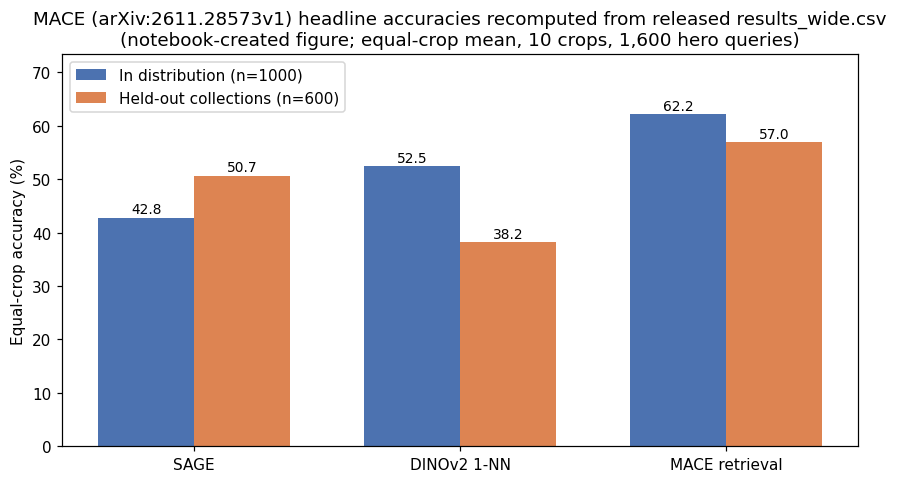

saved: /content/mace_accuracy_summary.png


In [ ]:
import matplotlib.pyplot as plt

def eq_crop(df, col):
    return float(np.mean([g[col].mean() for _, g in df.groupby("crop")]) * 100)

methods = [("SAGE", "sage"), ("DINOv2 1-NN", "dino_s0"), ("MACE retrieval", "mace")]
iid = [eq_crop(H[H.split == "iid"], c) for _, c in methods]
ood = [eq_crop(H[H.split == "ood"], c) for _, c in methods]

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=110)
x = np.arange(len(methods)); w = 0.36
ax.bar(x - w/2, iid, w, label="In distribution (n=%d)" % (H.split == "iid").sum(), color="#4C72B0")
ax.bar(x + w/2, ood, w, label="Held-out collections (n=%d)" % (H.split == "ood").sum(), color="#DD8452")
for xi, (a, b) in enumerate(zip(iid, ood)):
    ax.text(xi - w/2, a + 0.8, f"{a:.1f}", ha="center", fontsize=9)
    ax.text(xi + w/2, b + 0.8, f"{b:.1f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([m for m, _ in methods])
ax.set_ylabel("Equal-crop accuracy (%)")
ax.set_title("MACE (arXiv:2611.28573v1) headline accuracies recomputed from released results_wide.csv\n(notebook-created figure; equal-crop mean, 10 crops, 1,600 hero queries)")
ax.legend(); ax.set_ylim(0, max(iid + ood) * 1.18)
fig.tight_layout()
fig.savefig("/content/mace_accuracy_summary.png", dpi=110)
plt.show()
print("saved: /content/mace_accuracy_summary.png")

## Summary table and CSV export

Final verification summary: recomputed headline accuracies (this run, from the released CSV), the values documented in
`REPRODUCE.md`, and whether they agree to within rounding (0.05 points). The table is also exported as CSV so you can
keep the numbers.

**結果表（日本語）:** 再計算した主結果のまとめ表です。文書化された値と丸め誤差以内で一致するかを判定し、
CSV としてもエクスポートされます。

In [ ]:
doc = {"SAGE": (42.8, 50.7), "DINOv2 1-NN": (52.5, 38.2), "MACE retrieval": (62.2, 57.0)}
summary = pd.DataFrame(
    [(m, eq_crop(H[H.split == "iid"], c), eq_crop(H[H.split == "ood"], c), doc[m][0], doc[m][1])
     for m, c in methods],
    columns=["method", "recomputed_iid_acc", "recomputed_heldout_acc", "documented_iid_acc", "documented_heldout_acc"],
)
summary["matches_documented"] = [
    bool(abs(r.recomputed_iid_acc - r.documented_iid_acc) < 0.05 and abs(r.recomputed_heldout_acc - r.documented_heldout_acc) < 0.05)
    for r in summary.itertuples()
]
summary.to_csv("/content/mace_verification_summary.csv", index=False)
print(summary.to_string(index=False))
print("\nexported: /content/mace_verification_summary.csv")

        method  recomputed_iid_acc  recomputed_heldout_acc  documented_iid_acc  documented_heldout_acc  matches_documented
          SAGE                42.8               50.666667                42.8                    50.7                True
   DINOv2 1-NN                52.5               38.166667                52.5                    38.2                True
MACE retrieval                62.2               57.000000                62.2                    57.0                True

exported: /content/mace_verification_summary.csv


## Interpretation, validation record, and limitations

**What this run establishes.** With the authors' pinned code and released result files (commit `189523cac2da`):
1. `results/verify.py` recomputed the headline equal-crop accuracies and every value matched the released `results.json` at 1e-9.
2. `results/verify_extension.py` recomputed the 15 follow-up contrasts (+ post hoc Bugwood contrast); all point estimates matched the saved statistics.
3. `code/mace10/results.py` regenerated `results_wide.csv` and `results.json` from the released raw prediction packages; the regenerated statistics equal the released ones.

**What this does NOT establish.** This verifies the *recorded* results and their internal consistency. It does not rerun
any vision-language model: per `REPRODUCE.md`, fresh model calls need the frozen benchmark image release
(tag `v2.1-frozen-2026-11-03`), a signed-in Claude Code CLI, and ≈ USD 185 at list prices, so the underlying diagnoses are
taken as released. The authors also note repeat-run variance is unmeasured (sampling is not fixed by their CLI) and that
no plant pathologist reviewed the labels. The Hugging Face dataset `tirtho149/MACE-Bench` now lists 5,601 benchmark
images, while the repository README still says images are "not public yet" — this discrepancy does not affect the
verification above, but fresh reruns remain out of scope here.

**Scope/limitations (日本語):** 本ノートブックは公開済みの結果ファイルの再計算と整合確認であり、新しいモデル推論は行いません。
ブートストラップ区間の端数は著者コードと行順が異なるため末尾がずれることがあります（点推定値は一致）。GPU は不要です。

**Provenance.** Code and results: MACE-Bench/MACE-Bench.github.io @ `189523cac2da27a498cbdb2783dad6db930b18e9` (code MIT, results CC BY 4.0; images under their source licenses).
Paper: arXiv:2611.28573v1. The executed outputs in this notebook were produced on a fresh Colab CPU runtime; the notebook contains
no GPU-dependent cell. PhenoPaper investigation/flow records were used only as research guidance; every executed operation above maps to the pinned author code.